# Part 2 - Fine-tuning Stable Diffusion 1.5 with LoRA (rank 4 vs rank 32)

In [1]:
# Cell 1 - run information (required)
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '678da737', 'python': '3.12.10', 'torch': '2.11.0+cu128', 'gpu': 'NVIDIA GeForce RTX 5090', 'seed': 266}


In [2]:
import os, sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 120)

## 2.1 Data preparation

In [3]:
from p2_finetune import data_prep, prompts as P
stats = data_prep.clean_and_split(out_dir="work_p2/data"); print(stats)
test = data_prep.read_split("work_p2/data", "test"); train = data_prep.read_split("work_p2/data", "train")
PROMPTS = P.make_prompts([c for _, c in test], "prompts.json")   # commit prompts.json before training ends
pd.DataFrame(PROMPTS).head(20)

Repo card metadata block was not found. Setting CardData to empty.


{'total': 1221, 'corrupted': 0, 'exact_duplicates': 0, 'near_duplicates': 0, 'removed_total': 0, 'kept': 1221, 'test': 122, 'train': 1099}


,id,type,prompt
0,in00,in_domain,a dog in a blue shirt and white pants
1,in01,in_domain,a person in a room with green walls
2,in02,in_domain,a woman with long black hair and blue eyes
3,in03,in_domain,a woman with glasses and a red shirt
4,in04,in_domain,a girl with long blonde hair and blue eyes
5,in05,in_domain,a man with glasses and a hat on
6,in06,in_domain,a young boy in a purple shirt and black pants
7,in07,in_domain,a man in a fire with his hands clasped
8,in08,in_domain,a person wearing a hoodie and looking at the camera
9,in09,in_domain,a man with black hair and a brown vest


Dataset: Naruto BLIP captions (square-cropped to 512x512 - cropping can cut characters). Limitations/biases: (1) one franchise, mostly front-facing characters, so poor generalisation; (2) BLIP captions are short and sometimes wrong (e.g. 'a man with a sword'), which limits prompt alignment.

## 2.2 Two training runs (same data, steps, batch size, lr, seed)

In [4]:
from p2_finetune.train_lora import train
info1 = train("lora_r4", 4, "work_p2/data")
info2 = train("lora_r32", 32, "work_p2/data")
pd.DataFrame([info1, info2]).set_index("run")[["rank", "trainable_params", "learning_rate", "steps", "batch_size", "peak_gpu_mem_gb", "train_seconds", "gpu_hours"]]

C:\Users\sivasurya\Downloads\LAB2\p2_finetune\train_lora.py:69: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[lora_r4] step 0/1500 loss 0.2852


[lora_r4] step 100/1500 loss 0.0790


[lora_r4] step 200/1500 loss 0.0952


[lora_r4] step 300/1500 loss 0.0861


[lora_r4] step 400/1500 loss 0.0856


... (22 outputs left out)

[lora_r32] step 1200/1500 loss 0.0902


[lora_r32] step 1300/1500 loss 0.0926


[lora_r32] step 1400/1500 loss 0.0979


,rank,trainable_params,learning_rate,steps,batch_size,peak_gpu_mem_gb,train_seconds,gpu_hours
run,,,,,,,,
lora_r4,4,797184,0.0001,1500,4,2.66,519.4,0.144
lora_r32,32,6377472,0.0001,1500,4,2.73,728.3,0.202


In [5]:
# push to Hugging Face (needs HF_TOKEN in the environment; set repo ids first)
from p2_finetune.hf_upload import push_adapter
push_adapter("work_p2/runs/lora_r4",  "sivasuryachandran/sd15-naruto-lora-r4")
push_adapter("work_p2/runs/lora_r32", "sivasuryachandran/sd15-naruto-lora-r32", results_text="see report")

pytorch_lora_weights.safetensors:   0%|          | 0.00/3.23M [00:00<?, ?B/s]

pytorch_lora_weights.safetensors:   0%|          | 0.00/25.5M [00:00<?, ?B/s]

## 2.3 Generation: 20 prompts x 2 seeds x 3 models = 120 images

In [6]:
from p2_finetune.generate import generate_all, SETTINGS
print(SETTINGS)
META = generate_all({"base": None, "run1": "work_p2/runs/lora_r4", "run2": "work_p2/runs/lora_r32"}, PROMPTS)
len(META)

{'steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512, 'scheduler': 'DPMSolverMultistep'}


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


120

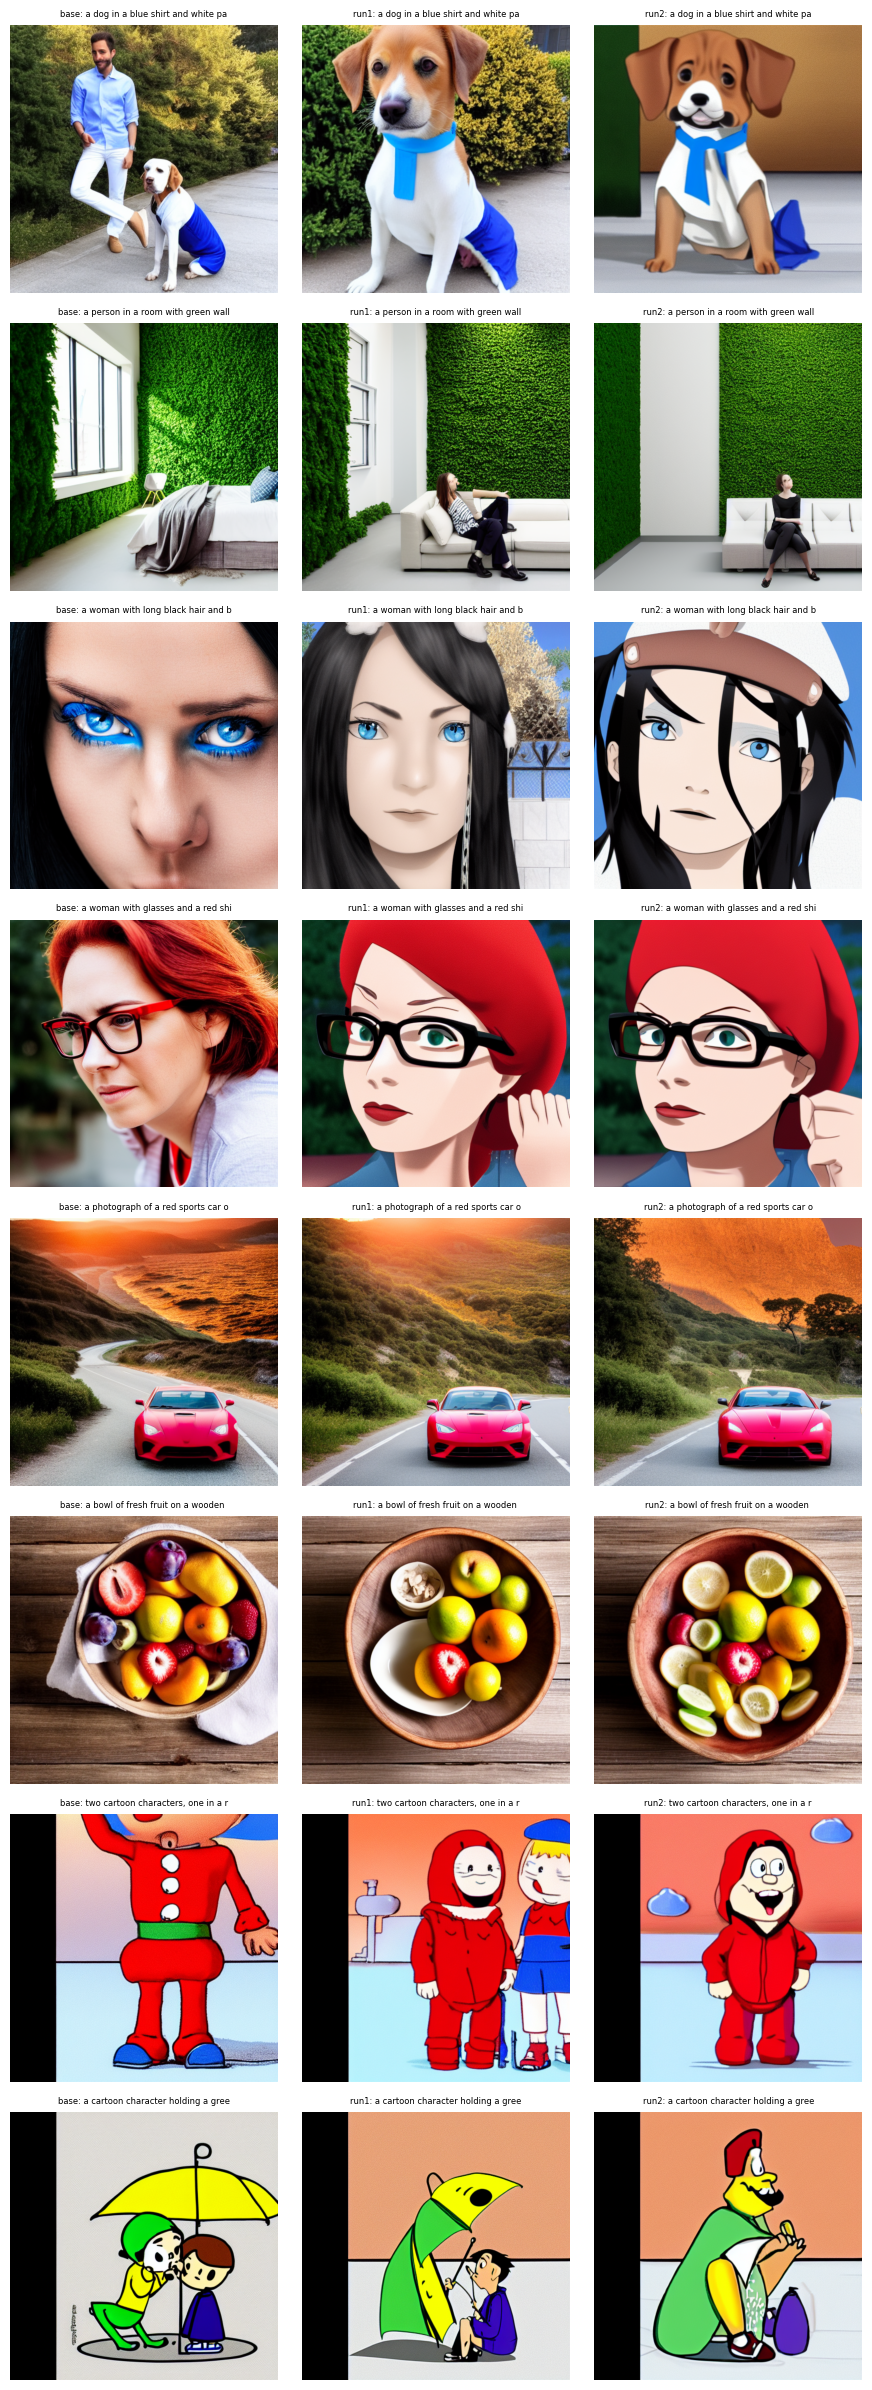

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
sel = [p for p in PROMPTS if p["type"] == "in_domain"][:4] + [p for p in PROMPTS if p["type"] == "out_of_domain"][:2] + [p for p in PROMPTS if p["type"] == "compositional"][:2]
fig, ax = plt.subplots(len(sel), 3, figsize=(9, 3 * len(sel)))
for r, p in enumerate(sel):
    for c, m in enumerate(["base", "run1", "run2"]):
        ax[r, c].imshow(Image.open(f"work_p2/images/{m}/{p['id']}_s0.png")); ax[r, c].axis("off")
        ax[r, c].set_title(f"{m}: {p['prompt'][:34]}", fontsize=6)
plt.tight_layout(); plt.savefig("p2_grid.png", dpi=120); plt.show()

In [8]:
# upload to a Hugging Face dataset (prompt, seed, model in metadata)
from p2_finetune.hf_upload import push_images; push_images(META, "sivasuryachandran/sd15-naruto-lora-generations")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

## 2.4 Evaluation: KID + CLIP (primary), LPIPS diversity (secondary), efficiency

In [9]:
from p2_finetune import evaluate as E
clip = E.Clip()
test_paths = [p for p, _ in test]; train_paths = [p for p, _ in data_prep.read_split("work_p2/data", "train")]
res = pd.DataFrame([E.summarize_model(clip, META, m, test_paths) for m in ["base", "run1", "run2"]]).set_index("model")
res["gpu_hours"] = [None, info1["gpu_hours"], info2["gpu_hours"]]
res["peak_gpu_mem_gb"] = [None, info1["peak_gpu_mem_gb"], info2["peak_gpu_mem_gb"]]
res

model.safetensors:  28%|##7       | 168M/605M [00:00<?, ?B/s]

C:\Users\sivasurya\Downloads\LAB2\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\sivasurya/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth


  0%|          | 0.00/91.2M [00:00<?, ?B/s]

  8%|▊         | 6.88M/91.2M [00:00<00:01, 70.8MB/s]

 15%|█▍        | 13.6M/91.2M [00:00<00:01, 48.9MB/s]

 21%|██        | 19.1M/91.2M [00:00<00:01, 51.8MB/s]

... (43 outputs left out)

 95%|█████████▍| 220M/233M [00:02<00:00, 102MB/s]

 99%|█████████▉| 231M/233M [00:02<00:00, 104MB/s]

100%|██████████| 233M/233M [00:02<00:00, 103MB/s]

,kid_mean,kid_std,clip_score,clip_in_domain,clip_out_of_domain,clip_compositional,lpips_diversity,nsfw_flagged,n_images,gpu_hours,peak_gpu_mem_gb
model,,,,,,,,,,,
base,0.123013,0.014058,33.348300,32.192351,33.520828,35.487670,0.821534,0,40,NaN,NaN
run1,0.045477,0.008765,31.761209,29.698086,32.069626,35.579039,0.794292,0,40,0.144,2.66
run2,0.025879,0.007384,30.882994,28.867377,32.620422,33.176800,0.800470,3,40,0.202,2.73


KID is computed from 20 in-domain generations vs the test images, so it is noisy (see std). Fill in which run is final after looking at the table and the human evaluation.

In [10]:
FINAL = "run1"   # choose after reviewing results; justify in the report
from p2_finetune.human_eval import build_sheet
build_sheet(META, final=FINAL)    # share work_p2/human_eval/pair_*.png + rating_sheet_TEMPLATE.csv with 3 raters
# from p2_finetune.human_eval import win_rate; win_rate("work_p2/human_eval", ["rater1.csv", "rater2.csv", "rater3.csv"])

### Failure modes (>= 2, with images)

base
   29.9 work_p2/images\base\ood04_s0.png | a modern glass skyscraper reflecting the clouds
   30.7 work_p2/images\base\comp04_s0.png | a character on the left looking at a character on the right, who is ho
   31.4 work_p2/images\base\comp04_s1.png | a character on the left looking at a character on the right, who is ho
run1
   26.7 work_p2/images\run1\ood04_s1.png | a modern glass skyscraper reflecting the clouds
   28.2 work_p2/images\run1\comp04_s0.png | a character on the left looking at a character on the right, who is ho
   28.5 work_p2/images\run1\ood00_s1.png | a photograph of a red sports car on a coastal highway at sunset
run2
   24.9 work_p2/images\run2\comp02_s0.png | three characters in a row: the left one in orange, the middle one in p
   29.0 work_p2/images\run2\ood04_s0.png | a modern glass skyscraper reflecting the clouds
   29.6 work_p2/images\run2\comp04_s1.png | a character on the left looking at a character on the right, who is ho


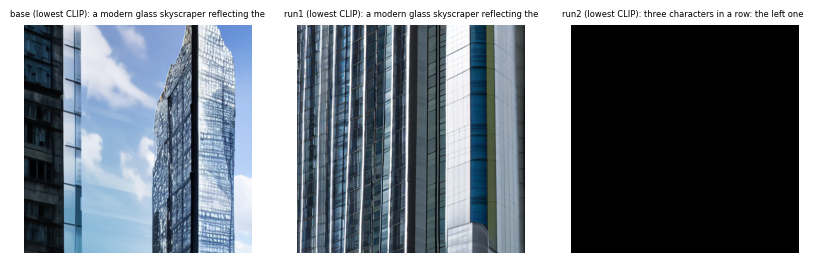

In [11]:
cand = E.failure_candidates(clip, META)
for m, rows in cand.items():
    print(m)
    for score, f, pr in rows: print("  ", round(score, 1), f, "|", pr[:70])
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
for a, (m, rows) in zip(ax, cand.items()):
    a.imshow(Image.open(rows[0][1])); a.set_title(f"{m} (lowest CLIP): {rows[0][2][:40]}", fontsize=6); a.axis("off")
plt.savefig("p2_failures.png", dpi=120); plt.show()

## C4 safety: license, NSFW filter, memorization

images flagged by the SD safety checker: {'base': 0, 'run1': 0, 'run2': 3}


C:\Users\sivasurya\Downloads\LAB2\.venv\Lib\site-packages\huggingface_hub\file_download.py:140: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sivasurya\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


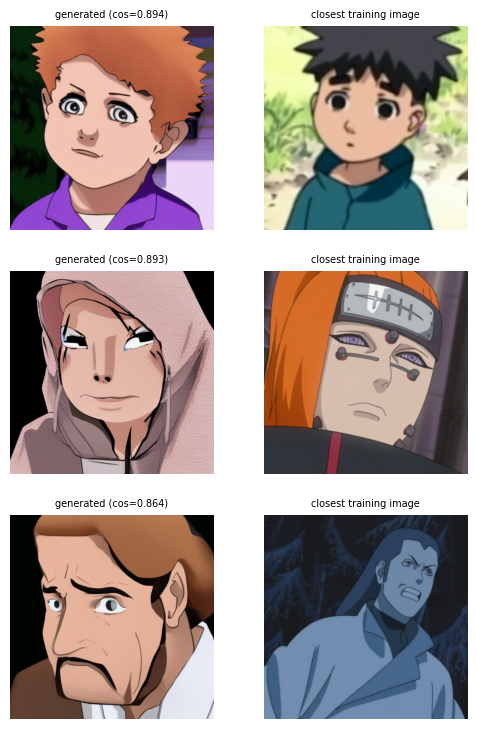

In [12]:
print("images flagged by the SD safety checker:", res["nsfw_flagged"].to_dict())
top3, allpairs = E.memorization(clip, META, FINAL, train_paths)
fig, ax = plt.subplots(3, 2, figsize=(6, 9))
for r, p in enumerate(top3):
    ax[r, 0].imshow(Image.open(p["gen"])); ax[r, 1].imshow(Image.open(p["train"]))
    ax[r, 0].set_title(f"generated (cos={p['cosine']:.3f})", fontsize=7); ax[r, 1].set_title("closest training image", fontsize=7)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.savefig("p2_memorization.png", dpi=120); plt.show()